# Milestone 1 — Data Understanding

## Research question
What can we learn about the structure and quality of the normal-operation and Fault 4 datasets before training any fault-detection model?

## Workflow
1. Set up the environment and load the data.
2. Validate data shape and numerical quality.
3. Explore distributions, time-series behaviour, and cross-variable correlations.
4. Rank variables by their standardized mean shift.
5. Summarize findings, limitations, and the next research question.

**Scope:** This notebook uses the training files `d00.dat` (normal) and `d04.dat` (Fault 4). Test files are checked for structural consistency only; model evaluation belongs to later milestones.


## 1. Set up the environment

Import the libraries used throughout this notebook.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)

print("NumPy version:", np.__version__)
print("pandas version:", pd.__version__)

NumPy version: 2.1.3
pandas version: 2.2.3


## 2. Download the dataset

**Source repository:** https://github.com/believe563/tennessee-eastman-profBraatz-database

The data files are space-delimited numerical arrays with 52 process variables. The source documentation describes a sampling interval of 3 minutes.

The next cell clones the repository only if it is not already present, making notebook reruns less likely to fail because the destination directory exists.


In [ ]:
from pathlib import Path
import subprocess

data_dir = Path("/content/tep_data")
if not data_dir.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/believe563/tennessee-eastman-profBraatz-database.git",
            str(data_dir),
        ],
        check=True,
    )
else:
    print(f"Using existing dataset directory: {data_dir}")


Check that the expected training and test files are available.


In [ ]:
data_dir = Path("/content/tep_data")

print("Dataset directory exists:", data_dir.exists())

print("Normal training file:", (data_dir / "d00.dat").exists())
print("Normal testing file:", (data_dir / "d00_te.dat").exists())

print("\nExample files:")
for path in sorted(data_dir.glob("d0*"))[:10]:
    print(path.name)

Dataset directory exists: True
Normal training file: True
Normal testing file: True

Example files:
d00.dat
d00_te.dat
d01.dat
d01_te.dat
d02.dat
d02_te.dat
d03.dat
d03_te.dat
d04.dat
d04_te.dat


## 3. Locate and load the data

We begin with two training files:
- `d00.dat` — normal operating condition.
- `d04.dat` — Fault 4 condition.

Each sample has 52 variables:
- `xmeas_1`–`xmeas_41`: measured process variables.
- `xmv_1`–`xmv_11`: manipulated variables.

The loader below normalizes orientation to **samples × variables** without truncating the data.


In [ ]:
def find_data_file(filename):
    matches = list(data_dir.rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"{filename} not found under {data_dir}"
        )

    return matches[0]


normal_path = find_data_file("d00.dat")
fault4_path = find_data_file("d04.dat")
normal_test_path = find_data_file("d00_te.dat")
fault4_test_path = find_data_file("d04_te.dat")

print("Normal training:", normal_path)
print("Fault 4 training:", fault4_path)

Normal training: /content/tep_data/d00.dat
Fault 4 training: /content/tep_data/d04.dat


`numpy.loadtxt` reads each space-delimited file into a NumPy array. Files may be stored in different orientations, so the loader checks which dimension contains the 52 variables and converts the result to **samples × variables**.


In [ ]:
def load_tep_data(path, expected_variables=52):
    data = np.loadtxt(path)

    # Ensure each row represents one time sample
    if data.shape[1] == expected_variables:
        return data
    elif data.shape[0] == expected_variables:
        return data.T
    else:
        raise ValueError(
            f"Unexpected data shape {data.shape} in {path}"
        )


raw_normal = load_tep_data(normal_path)
raw_fault4 = load_tep_data(fault4_path)

print("Normal shape:", raw_normal.shape)
print("Fault 4 shape:", raw_fault4.shape)

Normal shape: (500, 52)
Fault 4 shape: (480, 52)


## 4. Create labelled DataFrames

Each row represents one time sample and each column represents a process variable. Consistent column names make the later checks and plots easier to read.


In [ ]:
variable_names = (
    [f"xmeas_{i}" for i in range(1, 42)]
    + [f"xmv_{i}" for i in range(1, 12)]
)

df_normal = pd.DataFrame(
    raw_normal,
    columns=variable_names
)

df_fault4 = pd.DataFrame(
    raw_fault4,
    columns=variable_names
)

print("Normal:", df_normal.shape)
print("Fault 4:", df_fault4.shape)

display(df_normal.head())

Normal: (500, 52)
Fault 4: (480, 52)


,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,...,xmv_6,xmv_7,xmv_8,xmv_9,xmv_10,xmv_11
0,0.24987,3642.6,4539.6,9.2784,27.200,42.248,...,39.724,41.975,50.223,47.411,41.093,18.351
1,0.25118,3694.8,4513.8,9.2831,27.077,42.736,...,40.249,34.187,44.741,47.442,41.303,19.831
2,0.25185,3683.5,4504.9,9.4600,26.987,42.245,...,40.003,43.628,46.032,47.574,41.520,20.426
3,0.25147,3653.9,4531.9,9.3462,26.983,42.656,...,40.161,37.967,43.903,47.606,41.284,19.568
4,0.24107,3629.3,4527.0,9.3406,27.041,42.520,...,40.962,34.247,48.037,47.585,40.949,17.063


## 5. Validate data quality

Check shapes, data types, missing values, and infinite values before interpreting the measurements.


In [ ]:
print("Normal dataset shape:", df_normal.shape)
print("Fault 4 dataset shape:", df_fault4.shape)

print("\nNormal data types:")
print(df_normal.dtypes.value_counts())

print("\nMissing values in normal data:")
print(df_normal.isna().sum().sum())

print("\nMissing values in Fault 4 data:")
print(df_fault4.isna().sum().sum())

print("\nInfinite values in normal data:")
print(np.isinf(df_normal.to_numpy()).sum())

print("\nInfinite values in Fault 4 data:")
print(np.isinf(df_fault4.to_numpy()).sum())

Normal dataset shape: (500, 52)
Fault 4 dataset shape: (480, 52)

Normal data types:
float64    52
Name: count, dtype: int64

Missing values in normal data:
0

Missing values in Fault 4 data:
0

Infinite values in normal data:
0

Infinite values in Fault 4 data:
0


## 6. Descriptive statistics

Summary statistics help establish the scale and spread of each variable under normal operation. The table is descriptive; it does not by itself identify a fault detector.


In [ ]:
display(df_normal.describe().T)

,count,mean,std,min,25%,50%,75%,max
xmeas_1,500.0,0.251138,0.028551,0.180820,0.230590,0.250245,0.269275,0.342850
xmeas_2,500.0,3663.537800,32.031586,3559.500000,3643.050000,3663.650000,3684.625000,3754.700000
xmeas_3,500.0,4511.517200,31.724556,4419.800000,4488.575000,4512.300000,4534.700000,4600.700000
xmeas_4,500.0,9.344306,0.076514,9.128600,9.293000,9.343450,9.395350,9.592800
xmeas_5,500.0,26.907786,0.208664,26.280000,26.776000,26.899500,27.048000,27.529000
xmeas_6,500.0,42.338706,0.220975,41.659000,42.173750,42.353500,42.486000,42.925000
xmeas_7,500.0,2705.397400,5.263385,2690.500000,2702.900000,2705.900000,2709.500000,2715.800000
xmeas_8,500.0,74.984724,0.528206,73.617000,74.633750,74.979500,75.337000,76.750000
xmeas_9,500.0,120.399440,0.018654,120.350000,120.390000,120.400000,120.410000,120.450000
xmeas_10,500.0,0.337592,0.011688,0.305090,0.329445,0.337140,0.345668,0.370080


## 7. Initial time-series comparison

Start with four measured variables (`xmeas_1`–`xmeas_4`) to see whether their raw trajectories visibly differ between normal and Fault 4 runs. This is an initial visual check, not a systematic feature-selection procedure.


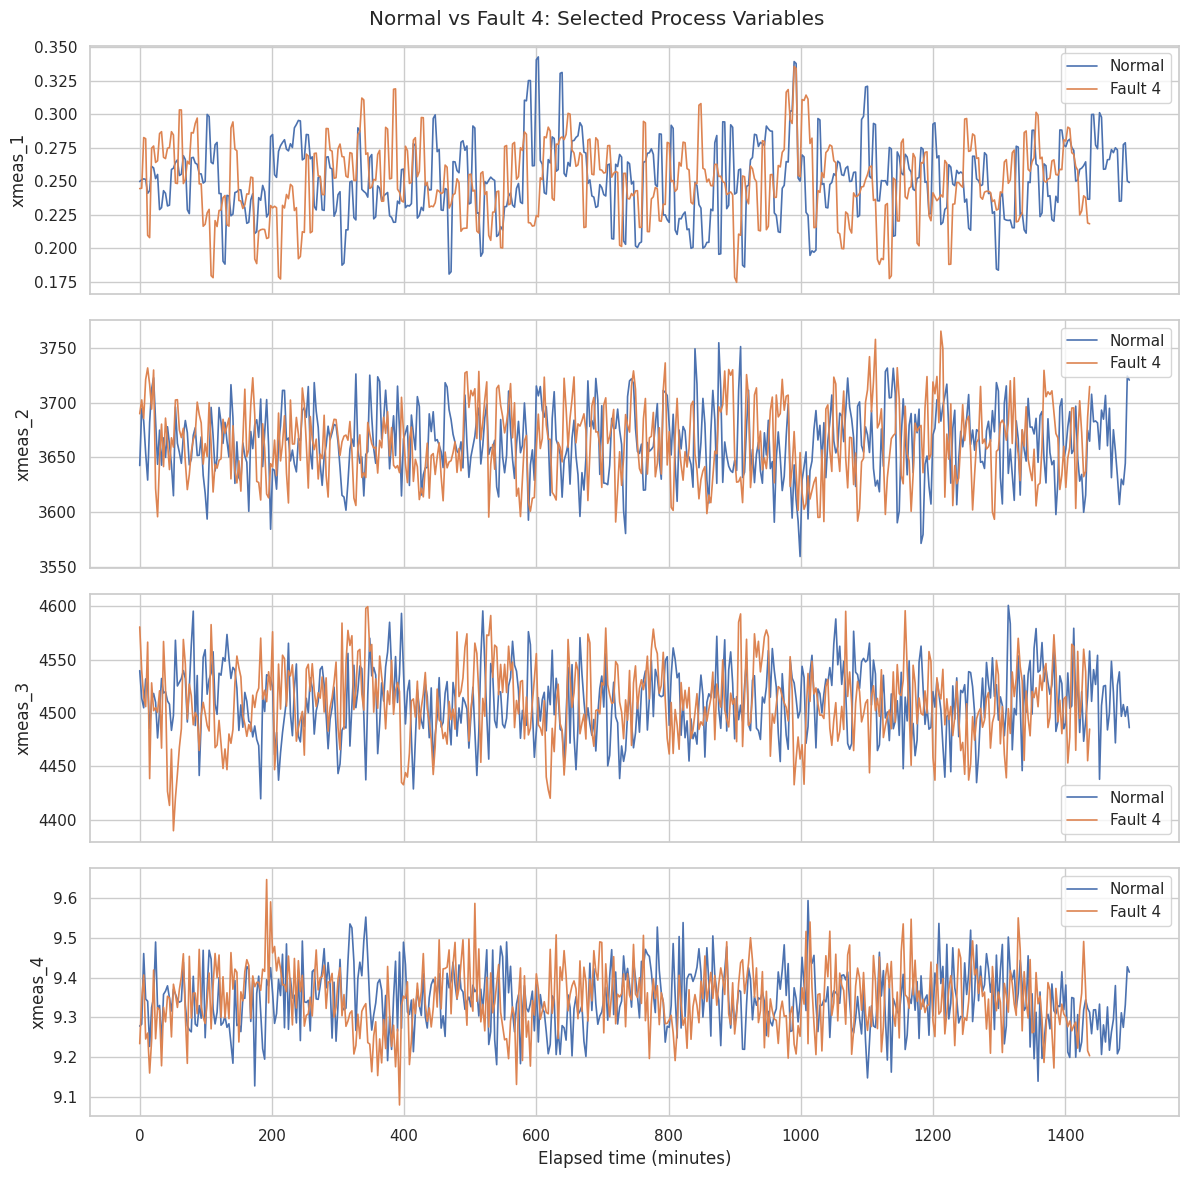

In [ ]:
selected_variables = [
    "xmeas_1",
    "xmeas_2",
    "xmeas_3",
    "xmeas_4",
]

fig, axes = plt.subplots(
    len(selected_variables),
    1,
    figsize=(12, 12),
    sharex=True
)

time_normal = np.arange(len(df_normal)) * 3   #3 minutes interval
time_fault4 = np.arange(len(df_fault4)) * 3

for ax, variable in zip(axes, selected_variables):
    ax.plot(
        time_normal,
        df_normal[variable],
        label="Normal",
        linewidth=1.2
    )

    ax.plot(
        time_fault4,
        df_fault4[variable],
        label="Fault 4",
        linewidth=1.2
    )

    ax.set_ylabel(variable)
    ax.legend()

axes[-1].set_xlabel("Elapsed time (minutes)")
fig.suptitle("Normal vs Fault 4: Selected Process Variables")
plt.tight_layout()
plt.show()

### Observation and interpretation

The selected traces overlap substantially in this raw comparison. This is not enough to conclude that Fault 4 is difficult to detect: only four variables are shown, and the runs have not been aligned to a verified fault-onset time.

**Next question:** Could multivariate relationships reveal differences that are not obvious from these individual traces?


## 8. Correlation structure

Chemical-process variables can change together. Compare the correlation matrices of ten selected measured variables under normal and Fault 4 conditions to explore whether their pairwise relationships differ.

This is an exploratory comparison: correlation differences do not establish causation or prove that a variable improves model performance.


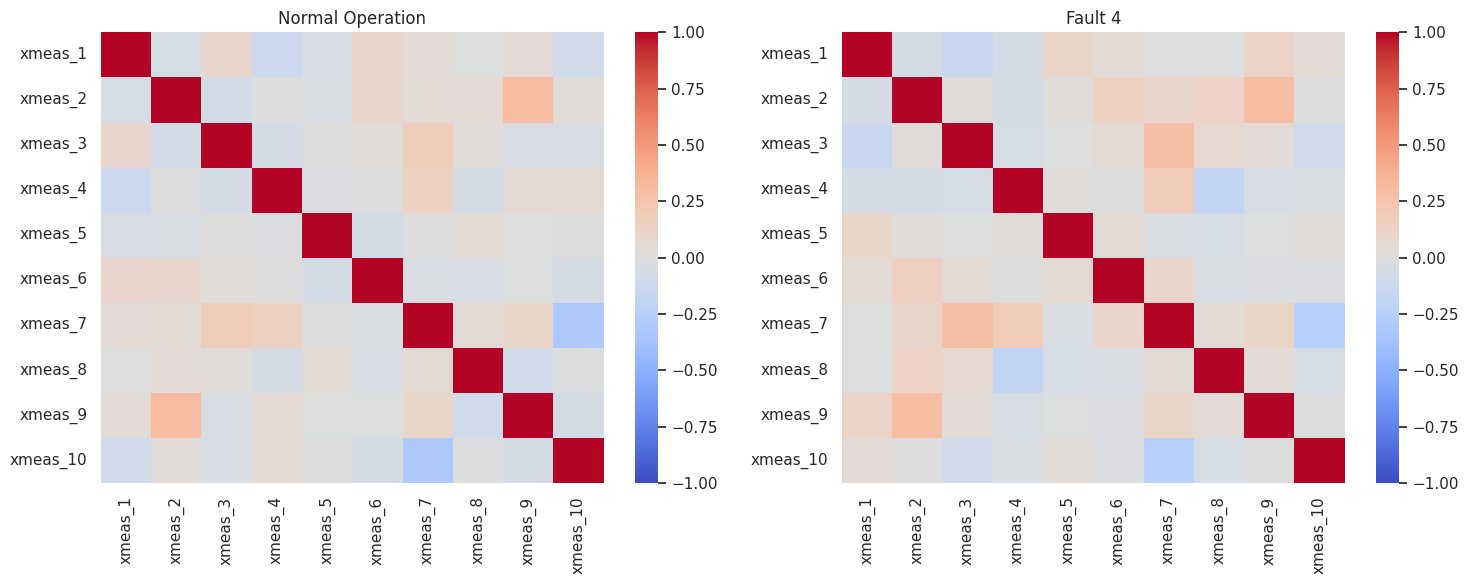

In [ ]:
corr_variables = [
    "xmeas_1",
    "xmeas_2",
    "xmeas_3",
    "xmeas_4",
    "xmeas_5",
    "xmeas_6",
    "xmeas_7",
    "xmeas_8",
    "xmeas_9",
    "xmeas_10",
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    df_normal[corr_variables].corr(),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[0]
)
axes[0].set_title("Normal Operation")

sns.heatmap(
    df_fault4[corr_variables].corr(),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title("Fault 4")

plt.tight_layout()
plt.show()

## 9. Check the test files' structure

Confirm that the normal and Fault 4 test files can also be loaded as samples × 52 variables. These checks establish structural consistency only; the test data are not used to fit anything in this EDA notebook.


In [ ]:
normal_test = load_tep_data(normal_test_path)
fault4_test = load_tep_data(fault4_test_path)

print("Normal training shape:", raw_normal.shape)
print("Normal test shape:", normal_test.shape)
print("Fault 4 training shape:", raw_fault4.shape)
print("Fault 4 test shape:", fault4_test.shape)

for name, array in {
    "normal training": raw_normal,
    "normal test": normal_test,
    "Fault 4 training": raw_fault4,
    "Fault 4 test": fault4_test,
}.items():
    assert array.ndim == 2, f"{name} is not a 2D array: {array.shape}"
    assert array.shape[1] == 52, f"{name} has unexpected shape: {array.shape}"

print("\nAll four files have 52 variables after orientation normalization.")


Normal training shape: (500, 52)
Normal test shape: (960, 52)
Fault 4 training shape: (480, 52)
Fault 4 test shape: (960, 52)

All four files have 52 variables after orientation normalization.


## 10. Rank variables by standardized mean shift

A standardized mean shift compares the difference in means relative to the pooled within-dataset standard deviation:

d_j = (x_Fault4,j - x_Normal,j) / s_p,j

where s_p,j is the pooled standard deviation for variable \(j\). We rank by the **absolute** shift to find variables whose average values differ most between the two training datasets, regardless of direction.

This is a descriptive screening statistic, not a trained detector and not evidence of causation.


In [ ]:
normal_mean = df_normal.mean()
fault_mean = df_fault4.mean()

normal_var = df_normal.var()
fault_var = df_fault4.var()

# Descriptive pooled standard deviation
pooled_std = np.sqrt(
    (
        (len(df_normal) - 1) * normal_var
        + (len(df_fault4) - 1) * fault_var
    )
    / (len(df_normal) + len(df_fault4) - 2)
)

effect = (fault_mean - normal_mean) / pooled_std

effect_table = pd.DataFrame({
    "normal_mean": normal_mean,
    "fault4_mean": fault_mean,
    "standardized_shift": effect,
    "abs_shift": effect.abs(),
}).sort_values("abs_shift", ascending=False)

display(effect_table.head(15).round(3))

,normal_mean,fault4_mean,standardized_shift,abs_shift
xmv_10,41.095,44.906,7.474,7.474
xmeas_19,230.282,233.325,0.411,0.411
xmv_9,47.461,48.246,0.407,0.407
xmeas_18,65.721,65.845,0.394,0.394
xmeas_34,2.259,2.266,0.282,0.282
xmeas_39,0.099,0.097,-0.184,0.184
xmv_2,54.006,53.943,-0.148,0.148
xmeas_40,53.647,53.722,0.147,0.147
xmv_11,18.216,18.013,-0.139,0.139
xmeas_29,33.001,32.959,-0.137,0.137


### Observation and interpretation

`xmv_10` has the largest absolute standardized mean shift in this comparison (about 7.474); the next-largest shifts are much smaller (`xmeas_19` and `xmv_9`, about 0.411 and 0.407 in the current output).

This makes `xmv_10` a useful candidate for follow-up investigation, but **does not establish** that it is a reliable detector or the cause of Fault 4. As a manipulated variable, it may reflect how the control system responds to a process disturbance.

**Next question:** What do the time-series traces of the largest-shift variables look like?


## 11. Inspect the largest-shift variables over time

Plot `xmv_10`, `xmeas_19`, and `xmeas_3` as a visual follow-up to the standardized-shift ranking. The plots use sample index because fault-onset alignment has not yet been verified in this notebook.


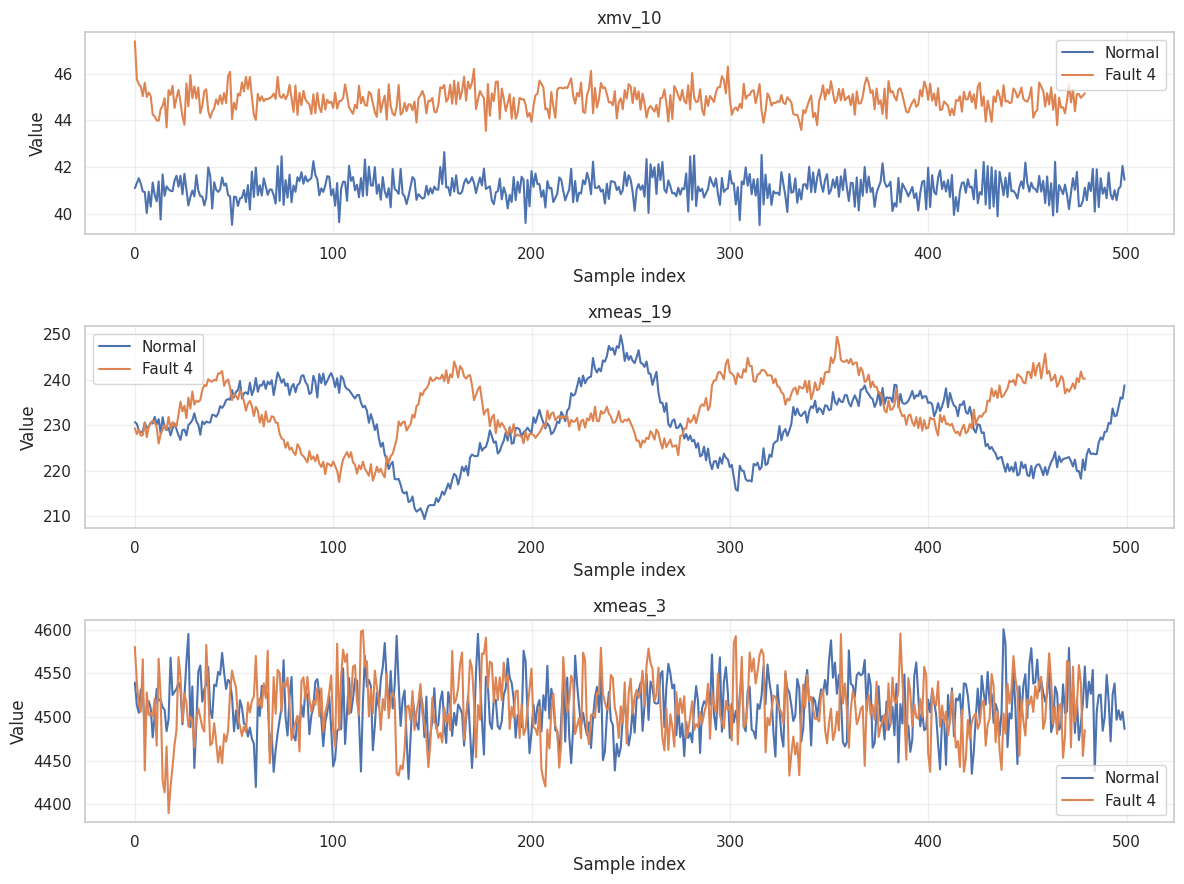

In [ ]:
variables_to_plot = [
    "xmv_10",
    "xmeas_19",
    "xmeas_3",
]

fig, axes = plt.subplots(
    len(variables_to_plot), 1,
    figsize=(12, 9)
)

for ax, var in zip(axes, variables_to_plot):
    ax.plot(df_normal[var].to_numpy(), label="Normal")
    ax.plot(df_fault4[var].to_numpy(), label="Fault 4")
    ax.set_title(var)
    ax.set_xlabel("Sample index")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Milestone 1 summary

### Findings
- The selected normal and Fault 4 training datasets are loaded as numerical arrays with 52 variables.
- The normal training file has 500 samples and the Fault 4 training file has 480 samples in the current data files; this differs from the expected file description and should be documented rather than silently corrected.
- The largest absolute standardized mean shift is observed for `xmv_10`; `xmeas_19` and `xmv_9` have much smaller shifts.
- The first four selected measured-variable traces overlap substantially in the raw comparison.

### Limitations
- Variable IDs have not yet been mapped to physical process names.
- Fault-onset timing and alignment conventions have not been verified here.
- Correlations and standardized mean shifts are exploratory statistics; neither establishes causality or predictive performance.
- No model has been trained or evaluated in this milestone.

### Transition to Milestone 2
The EDA suggests that some variables—especially `xmv_10`—may carry a strong signal for distinguishing normal operation from Fault 4. Milestone 2 will test this hypothesis with baseline fault-detection models and evaluate performance using an explicit validation protocol.
